In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

data = load_breast_cancer()
X, y = data.data, data.target
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=1)

In [2]:
depths = range(1, 11)
train_acc = []
test_acc = []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=1).fit(Xtr, ytr)
    train_acc.append(tree.score(Xtr, ytr))
    test_acc.append(tree.score(Xte, yte))

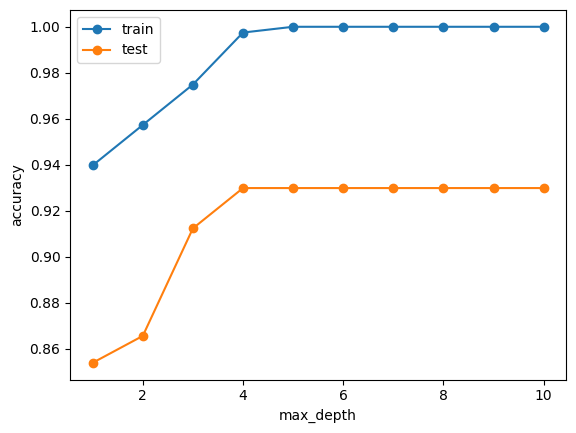

In [3]:
plt.plot(depths, train_acc, marker="o", label="train")
plt.plot(depths, test_acc, marker="o", label="test")
plt.xlabel("max_depth")
plt.ylabel("accuracy")
plt.legend()
plt.show()

In [4]:

tree = DecisionTreeClassifier(random_state=1).fit(Xtr, ytr)
rf = RandomForestClassifier(n_estimators=100, random_state=1).fit(Xtr, ytr)
print("Single tree:", round(tree.score(Xte, yte), 3))
print("Random forest:", round(rf.score(Xte, yte), 3))

Single tree: 0.93
Random forest: 0.947


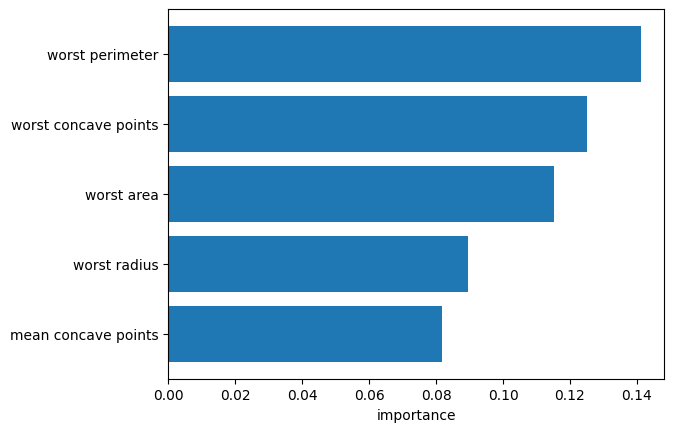

In [5]:
top = rf.feature_importances_.argsort()[-5:]
plt.barh(data.feature_names[top], rf.feature_importances_[top])
plt.xlabel("importance")
plt.show()